In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'MRFG3.SA'
papeis_adicionais = ['JBSS3.SA', 'BRFS3.SA', 'BEEF3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
#df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[MRFG3.SA] Cache existente cobre de 2020-01-02 a 2025-07-09.
[MRFG3.SA] Cache NÃO cobre período solicitado. Download total necessário.
[MRFG3.SA] Iniciando download de dados (lógica de atualização/complemento)...
[MRFG3.SA] Período de download yfinance: 2020-01-01 a 2025-07-14
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[MRFG3.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[MRFG3.SA] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1.00%).
[MRFG3.SA] Cache principal ATUALIZADO com dados frescos: /palpiteiro/dados\MRFG3.csv
[MRFG3.SA] Retornando 613 linhas para o período solicitado.
✅ Usando cache local: /palpiteiro/dados\macro_20220122_20250711.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-07-10.
[^BVSP] Cache cobre período solicitado (2023-01-22 a 2025-07-10).
[^BVSP] Garantindo atualização dos últimos 5 dias do cach

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_BRFS3,adc_high_BRFS3,adc_low_BRFS3,adc_close_BRFS3,adc_adj_close_BRFS3,adc_volume_BRFS3,adc_pct_change_BRFS3,adc_vol_BRFS3,adc_rsi_BRFS3,adc_macd_BRFS3,adc_macd_signal_BRFS3,adc_macd_hist_BRFS3,adc_tr_BRFS3,adc_atr_BRFS3,adc_atr_pct_BRFS3,adc_tr_pct_BRFS3,adc_mm5_BRFS3,adc_mm20_BRFS3,adc_open_BEEF3,adc_high_BEEF3,adc_low_BEEF3,adc_close_BEEF3,adc_adj_close_BEEF3,adc_volume_BEEF3,adc_pct_change_BEEF3,adc_vol_BEEF3,adc_rsi_BEEF3,adc_macd_BEEF3,adc_macd_signal_BEEF3,adc_macd_hist_BEEF3,adc_tr_BEEF3,adc_atr_BEEF3,adc_atr_pct_BEEF3,adc_tr_pct_BEEF3,adc_mm5_BEEF3,adc_mm20_BEEF3
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-26,22.760000,23.080000,22.530001,22.910000,22.910000,5893500,0.006590,0.025586,42.157311,0.043263,0.455284,-0.412020,0.549999,0.988139,0.043131,0.024007,23.424,24.7025,15.0,0.26,5.5145,135767.000,137353.000,135756.00000,137114.00000,137114.00000,7773826,20.000000,20.190001,19.809999,20.100000,20.100000,3434700,0.004498,0.028973,43.916635,-0.057591,0.016146,-0.073737,0.380001,0.886225,0.044091,0.018906,20.682,20.7130,4.86,4.89,4.81,4.86,4.86,10252700,0.010395,0.021940,43.691824,-0.142553,-0.161686,0.019133,0.08,0.193152,0.039743,0.016461,4.818,4.9260
2025-06-27,22.770000,22.820000,21.809999,22.500000,22.500000,7730800,-0.017896,0.025689,39.636022,-0.079456,0.348336,-0.427791,1.100000,0.996129,0.044272,0.048889,23.260,24.5350,15.0,0.26,5.4759,137113.000,137209.000,136469.00000,136866.00000,136866.00000,3731569,19.910000,19.920000,19.480000,19.900000,19.900000,5960100,-0.009950,0.027624,42.271101,-0.114526,-0.009988,-0.104538,0.620001,0.867209,0.043578,0.031156,20.504,20.6800,4.85,4.86,4.77,4.82,4.82,9226100,-0.008230,0.021868,42.449713,-0.136685,-0.156686,0.020001,0.09,0.185784,0.038544,0.018672,4.808,4.9160
2025-06-30,22.340000,22.990000,22.180000,22.900000,22.900000,4043800,0.017778,0.027250,43.204819,-0.142788,0.250111,-0.392899,0.809999,0.982834,0.042919,0.035371,22.968,24.4095,15.0,0.26,5.4571,136865.000,139103.000,136430.00000,138855.00000,138855.00000,4715665,19.870001,20.340000,19.620001,20.139999,20.139999,4525400,0.012060,0.027420,44.937339,-0.138683,-0.035727,-0.102956,0.719999,0.856694,0.042537,0.035750,20.180,20.6720,4.82,4.91,4.80,4.90,4.90,8213600,0.016597,0.018095,45.770281,-0.124147,-0.150178,0.026031,0.11,0.180371,0.036810,0.022449,4.826,4.9090
2025-07-01,22.910000,22.990000,21.900000,22.600000,22.600000,8021500,-0.013100,0.027267,41.235740,-0.214712,0.157146,-0.371859,1.090000,0.990489,0.043827,0.048230,22.734,24.2705,15.0,0.26,5.4511,138855.000,139695.000,138855.00000,139549.00000,139549.00000,2903180,20.209999,20.209999,19.629999,20.000000,20.000000,9353100,-0.006951,0.026561,43.670295,-0.167198,-0.062021,-0.105176,0.580000,0.836930,0.041847,0.029000,20.030,20.6470,4.93,5.07,4.89,5.01,5.01,15824100,0.022449,0.019057,50.038881,-0.104135,-0.140969,0.036835,0.18,0.180345,0.035997,0.035928,4.880,4.9030
2025-07-02,22.650000,22.660000,22.010000,22.129999,22.129999,6274300,-0.020797,0.027099,38.291352,-0.306109,0.064495,-0.370604,0.650000,0.966168,0.043659,0.029372,22.608,24.1140,15.0,0.26,5.4512,139586.000,140049.000,138384.00000,139051.00000,139051.00000,3619807,20.000000,20.010000,19.620001,19.620001,19.620001,3999800,-0.019000,0.027072,40.345104,-0.217946,-0.093206,-0.124739,0.389999,0.805007,0.041030,0.019878,19.952,20.6030,5.05,5.08,4.87,4.99,4.99,14506500,-0.003992,0.016049,49.279352,-0.088864,-0.130548,0.041684,0.21,0.182463,0.036566,0.042084,4.916,4.9000
2025-07-03,22.260000,22.400000,21.940001,21.940001,21.940001,2772600,-0.008586,0.026967,37.136933,-0.389385,-0.026281,-0.363104,0.459999,0.930013,0.042389,0.020966,22.414,23.9480,15.0,0.26,5.4208,139051.000,141304.000,139051.00000,140928.00000,140928.00000,3879378,19.670000,19.740000,19.190001,19.190001,19.190

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-26,0.988139,0.043131,0.549999,0.024007
2025-06-27,0.996129,0.044272,1.100000,0.048889
2025-06-30,0.982834,0.042919,0.809999,0.035371
2025-07-01,0.990489,0.043827,1.090000,0.048230
2025-07-02,0.966168,0.043659,0.650000,0.029372
2025-07-03,0.930013,0.042389,0.459999,0.020966
2025-07-04,0.900727,0.040519,0.520000,0.023392
2025-07-07,0.924960,0.039972,1.240000,0.053587
2025-07-08,0.926749,0.039136,0.949999,0.040118


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 4.52%
Valorização sugerida: 6.78%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [9]:
valorizacao = 0.07
stop_loss = 0.05
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [10]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

#0.0    0.789474
#1.0    0.210526

Target
0.0    0.723684
1.0    0.276316
Name: proportion, dtype: float64

In [11]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
lista_f1_treino = []
lista_f1_validacao = []
lista_pr_auc_treino = []
lista_pr_auc_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    lista_f1_treino.append(f1_score_treino)
    lista_f1_validacao.append(f1_score_validacao)

    lista_pr_auc_treino.append(pr_auc_treino)
    lista_pr_auc_validacao.append(pr_auc_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': lista_f1_treino,
    'F1 Validação': lista_f1_validacao,
    'PR AUC Treino': lista_pr_auc_treino,
    'PR AUC Validação': lista_pr_auc_validacao
})

INFO: Papéis adicionais detectados para features: ['BRFS3', 'BEEF3']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.595
AUC na validação: 0.730
Diferença AUC (Treino - Validação): -0.135
PR AUC no treino: 0.468
PR AUC na validação: 0.639
Diferença PR AUC (Treino - Validação): -0.171
F1 Score no treino: 0.381
F1 Score na validação: 0.630
INFO: Papéis adicionais detectados para features: ['BRFS3', 'BEEF3']
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.608
AUC na validação: 0.666
Diferença AUC (Treino - Validação): -0.057
PR AUC no treino: 0.454
PR AUC na validação: 0.514
Diferença PR AUC (Treino - Validação): -0.060
F1 Score no treino: 0.391
F1 Score na validação: 0.601
INFO: Papéis adicionais detectados para features: ['BRFS3', 'BEEF3']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.553
AUC na validação: 0.680
Diferença AUC (Treino - Validação): -0.127
PR AUC no treino: 0.380
PR AUC na validação: 0.624
Diferença PR AUC (Treino - Validação): -0.244
F1 Score no treino: 0.308
F1 Score na validação: 0.610
INFO: Papéis adicionais detectados para features: ['BRFS3', 'BEEF3']


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.628
AUC na validação: 0.520
Diferença AUC (Treino - Validação): 0.108
PROVÁVEL OVERFITTING
PR AUC no treino: 0.472
PR AUC na validação: 0.466
Diferença PR AUC (Treino - Validação): 0.006
F1 Score no treino: 0.345
F1 Score na validação: 0.323


In [12]:
df_resultados.sort_values(by='PR AUC Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação,PR AUC Treino,PR AUC Validação
0,6,0.380540,0.629731,0.468237,0.638961
4,30,0.308464,0.610290,0.379613,0.624035
1,10,0.391398,0.600562,0.453927,0.513858
5,60,0.345468,0.323335,0.472351,0.466002
3,20,0.304203,0.609227,0.375451,0.456615
2,15,0.304151,0.426006,0.416153,0.420684


In [13]:
# Preparar X e y para treino
DIAS_JANELA_X = 6  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['BRFS3', 'BEEF3']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [14]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['macd_ultimo', 'ibov_std', 'close_std', 'close_std_norm_atr_principal', 'close_max', 'macd_mean', 'close_mean', 'macd_signal_ultimo', 'rsi_mean']
Colunas restantes após filtragem: 72


In [15]:
X_train.tail()

,close_min,close_trend,retorno_desde_mudanca_close,close_amplitude,close_dist_min,close_ult_vs_mm_janela,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,retorno_acumulado,dias_alta_pct,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_pct_ultimo,rsi_std,rsi_ultimo,macd_std,macd_signal_mean,macd_signal_std,macd_hist_mean,macd_hist_std,macd_hist_ultimo,tr_mean,tr_std,tr_ultimo,tr_pct_mean,tr_pct_std,tr_pct_ultimo,adc_close_trend_BRFS3,adc_ret_acum_BRFS3,adc_rsi_ultimo_BRFS3,adc_atr_pct_ultimo_BRFS3,adc_macd_hist_ultimo_BRFS3,adc_correl_com_principal_BRFS3,adc_close_trend_BEEF3,adc_ret_acum_BEEF3,adc_rsi_ultimo_BEEF3,adc_atr_pct_ultimo_BEEF3,adc_macd_hist_ultimo_BEEF3,adc_correl_com_principal_BEEF3,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_ret_acum_mean_geral_janela,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,retorno_desde_mudanca_ibov,ibov_amplitude,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean,atr_ultimo,macd_std_norm_atr_principal,macd_ultimo_norm_atr_principal,macd_signal_std_norm_atr_principal,macd_signal_ultimo_norm_atr_principal,macd_hist_std_norm_atr_principal,macd_hist_ultimo_norm_atr_principal,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,close_amplitude_norm_atr_principal,adc_atr_pct_mean_geral_ultimo
2025-02-12,14.62,-0.043714,0.000000,0.62,0.00,-0.388333,-0.046688,-0.021127,-0.000969,0.025721,-0.024683,0.666667,0.333333,0.015118,-0.033145,7.071583e+06,9.354413e+05,-414745.714286,-0.132316,0.044017,2.460588,37.953565,0.014310,-0.423054,0.004233,-0.011050,0.015571,-0.007685,0.511667,0.203413,0.820000,0.034273,0.014203,0.056088,-0.103429,-0.038041,32.323315,0.039756,0.000971,0.897190,-0.038857,-0.047930,36.922210,0.045436,-0.011053,0.814448,12.30,0.188618,-0.042986,13.25,0.16,5.7711,-0.003951,0.014695,-0.001332,-112.171429,0.000000,2142.0,0.978155,2.186840,-0.000785,0.643535,0.022237,-0.673256,0.006577,-0.661315,0.024195,-0.011941,0.316086,1.274211,0.963428,0.042596
2025-02-13,14.15,-0.170000,-0.032148,1.09,0.00,-0.718334,-0.074195,-0.031929,-0.009269,0.026532,-0.070913,0.500000,0.500000,0.014274,-0.032812,6.700300e+06,5.809082e+05,-207897.142857,-0.048490,0.045108,3.557669,34.232022,0.025437,-0.426584,0.005960,-0.014121,0.020806,-0.047636,0.538333,0.197830,0.570000,0.036429,0.013921,0.040283,-0.286286,-0.080302,28.511790,0.041916,-0.061474,0.908374,-0.056571,-0.079399,35.207928,0.044642,-0.019223,0.891686,11.88,0.191077,-0.079851,13.25,0.16,5.7788,0.000291,0.010606,0.000000,-189.771429,0.000000,2142.0,0.763820,1.699992,-0.010700,0.638283,0.039853,-0.760047,0.009338,-0.685415,0.032596,-0.074632,0.309941,0.893021,1.707708,0.043279
2025-02-14,14.15,-0.158857,0.000000,1.09,0.29,-0.296667,-0.051996,-0.033876,-0.008522,0.027435,-0.026954,0.500000,0.500000,0.015769,-0.032812,7.003383e+06,1.082693e+06,185568.571429,0.272057,0.044062,3.421116,38.255079,0.033697,-0.431539,0.010037,-0.019819,0.024883,-0.047685,0.591667,0.156258,0.610000,0.040296,0.011052,0.042244,-0.273429,-0.030039,34.528636,0.041813,-0.053930,0.930872,-0.010286,0.018018,43.351352,0.043295,-0.007130,0.881570,12.27,0.176854,-0.006010,13.25,0.16,5.7283,-0.004306,0.020489,0.000000,391.200000,0.026984,3839.0,0.807060,1.509183,-0.013872,0.636262,0.052961,-0.781272,0.015774,-0.706327,0.039107,-0.074945,0.245588,0.958723,1.713130,0.042554
2025-02-17,14.15,-0.222000,0.000000,1.09,0.00,-0.471667,-0.066653,-0.042248,-0.007601,0.026833,-0.064772,0.500000,0.500000,0.015769,-0.030971,6.618150e+06,1.471515e+06,-182717.142857,-0.307828,0.044984,3.676586,35.890745,0.044775,-0.437978,0.016093,-0.025756,0.029837,-0.059625,0.583333,0.151217,0.640000,0.040085,0.010921,0.045230,-0.372286,-0.085714,31.900079,0.041943,-0.069798,0.931234,0.020000,0.040179,47.663323,0.042520,0.011301,0.752567,12.09,0.170389,-0.022768,13.25,0.16,5.7105,-0.014151,0.030643,-0.003107,629.885714,0.032191,4489.0,0.873024,1.459410,-0.020755,0.636529,0.0

# LogisticRegression

In [16]:
modelo_rl = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2}, C=0.01)
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.602
AUC na validação: 0.716
Diferença AUC (Treino - Validação): -0.114
PR AUC no treino: 0.483
PR AUC na validação: 0.627
Diferença PR AUC (Treino - Validação): -0.145
F1 Score no treino: 0.307
F1 Score na validação: 0.631


(np.float64(0.6015675887311102),
 np.float64(0.7158196534032473),
 np.float64(-0.11425206467213711),
 np.float64(0.4825253351030958),
 np.float64(0.6270414450208329),
 np.float64(0.30666165427690556),
 np.float64(0.6308932955712262))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: e92ec350544e4f9da2d2180366ac28df para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.612
AUC na validação: 0.678

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.602
  Precisão média (em 425 janelas com previsão positiva): 0.402
  Recall médio: 0.281

Calibrando thresholds para precisão mínima de 0.70...

Threshold Ideal Selecionado: 0.60
  Precisão Média Esperada: 70.32%
  Recall Médio Esperado: 13.84%
  Janelas Usadas para Precisão: 284.0

Threshold ideal baseado em mínimo recall ou precisão: 0.60

--- Conjunto de Validação --- Janelas
Precisão média (em 59 janelas com previsão positiva): 0.611
Recall médio: 0.420
Sinais de compra presentes na vallidação: 32.0
Sinais de compra previstos na validação: 18
Modelo MRFG3.SA_6dias_x_0.

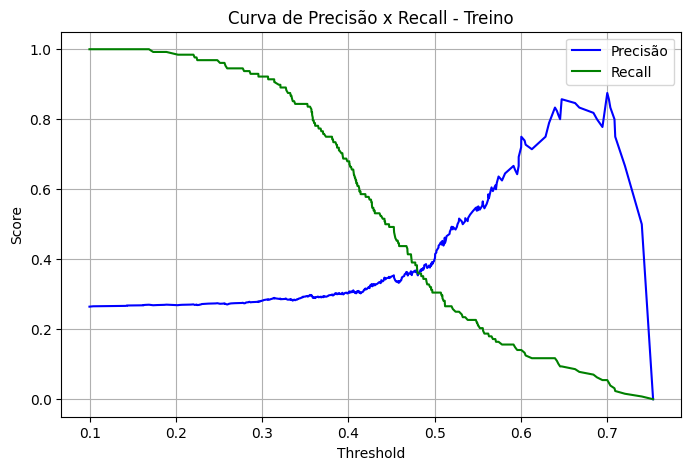

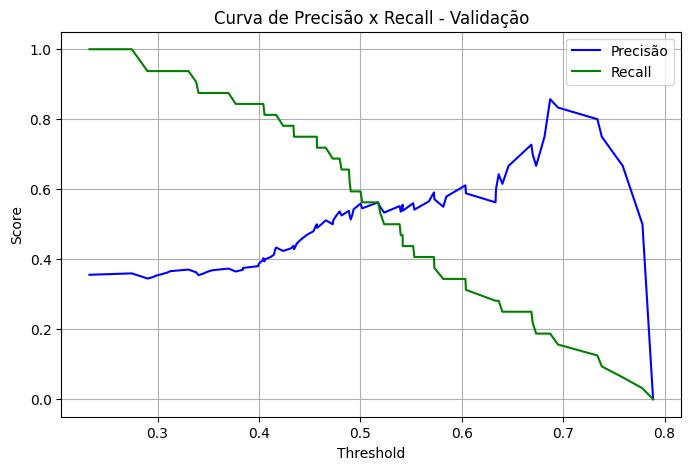

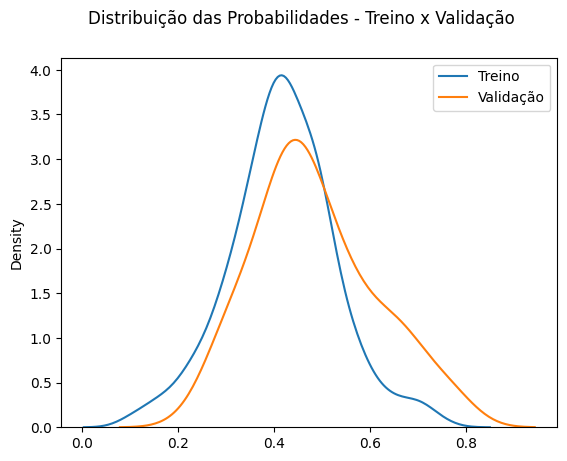

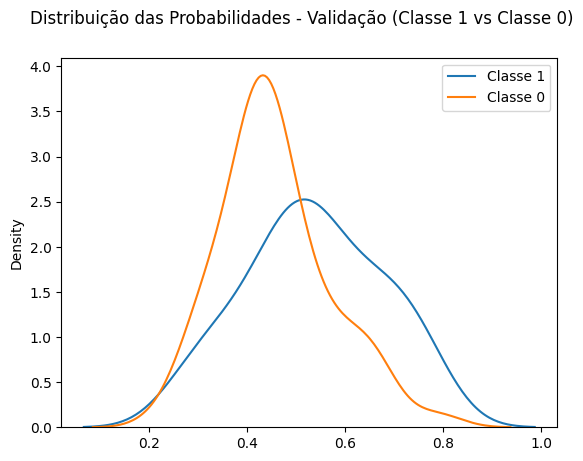

In [17]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [18]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
57,ibov_amplitude,1.969301e-04,1.969301e-04
55,ibov_trend,1.441042e-04,1.441042e-04
21,rsi_ultimo,-4.649460e-06,4.649460e-06
42,adc_rsi_ultimo_BEEF3,-4.176238e-06,4.176238e-06
36,adc_rsi_ultimo_BRFS3,-3.247647e-06,3.247647e-06
0,close_min,-1.871250e-06,1.871250e-06
59,beta_papel_ibov,1.302623e-06,1.302623e-06
46,adc_close_mean_geral_ultimo,-1.223007e-06,1.223007e-06
20,rsi_std,9.465173e-07,9.465173e-07
70,close_amplitude_norm_atr_principal,4.821416e-07,4.821416e-07


In [19]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k)['Feature'].tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2})
            modelo.fit(X_train[colunas_selecionadas], y_train )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, df_importancias)

In [20]:
resultados_precisao

{5: np.float64(0.6431703944203945),
 10: np.float64(1.0),
 15: np.float64(0.7224728487886383),
 20: np.float64(0.5916451946889254),
 25: np.float64(0.5916451946889254),
 30: np.float64(0.5916451946889254),
 35: np.float64(0.5916451946889254),
 40: np.float64(0.5916451946889254),
 45: np.float64(0.5916451946889254),
 50: np.float64(0.5916451946889254)}

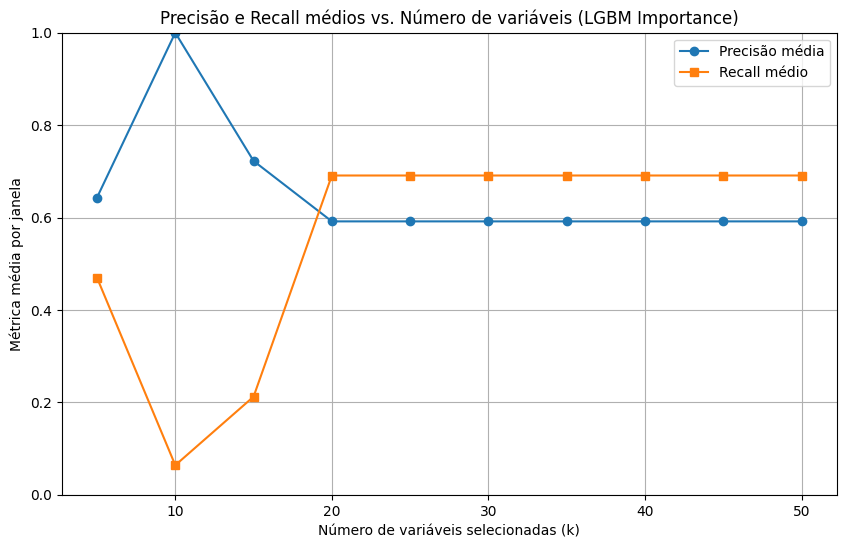

In [21]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [22]:
n_features = 20
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['ibov_amplitude',
 'ibov_trend',
 'rsi_ultimo',
 'adc_rsi_ultimo_BEEF3',
 'adc_rsi_ultimo_BRFS3',
 'close_min',
 'beta_papel_ibov',
 'adc_close_mean_geral_ultimo',
 'rsi_std',
 'close_amplitude_norm_atr_principal',
 'selic_ultimo',
 'adc_correl_com_principal_BEEF3',
 'dolar_ultimo',
 'macd_signal_ultimo_norm_atr_principal',
 'correl_papel_ibov',
 'adc_correl_com_principal_BRFS3',
 'macd_ultimo_norm_atr_principal',
 'volume_mean',
 'volume_std',
 'volume_trend']

In [23]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [24]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1,1:2}, C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.602
AUC na validação: 0.716
Diferença AUC (Treino - Validação): -0.114
PR AUC no treino: 0.483
PR AUC na validação: 0.627
Diferença PR AUC (Treino - Validação): -0.145
F1 Score no treino: 0.307
F1 Score na validação: 0.631


(np.float64(0.6015675887311102),
 np.float64(0.7158196534032473),
 np.float64(-0.11425206467213711),
 np.float64(0.4825253351030958),
 np.float64(0.6270414450208329),
 np.float64(0.30666165427690556),
 np.float64(0.6308932955712262))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: 27fa9278f8774596bf84a056ff02a139 para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.612
AUC na validação: 0.678

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.602
  Precisão média (em 425 janelas com previsão positiva): 0.402
  Recall médio: 0.281

Calibrando thresholds para precisão mínima de 0.70...

Threshold Ideal Selecionado: 0.60
  Precisão Média Esperada: 70.32%
  Recall Médio Esperado: 13.84%
  Janelas Usadas para Precisão: 284.0

Threshold ideal baseado em mínimo recall ou precisão: 0.60

--- Conjunto de Validação --- Janelas
Precisão média (em 59 janelas com previsão positiva): 0.611
Recall médio: 0.420
Sinais de compra presentes na vallidação: 32.0
Sinais de compra previstos na validação: 18
Modelo MRFG3.SA_6dias_x_0.

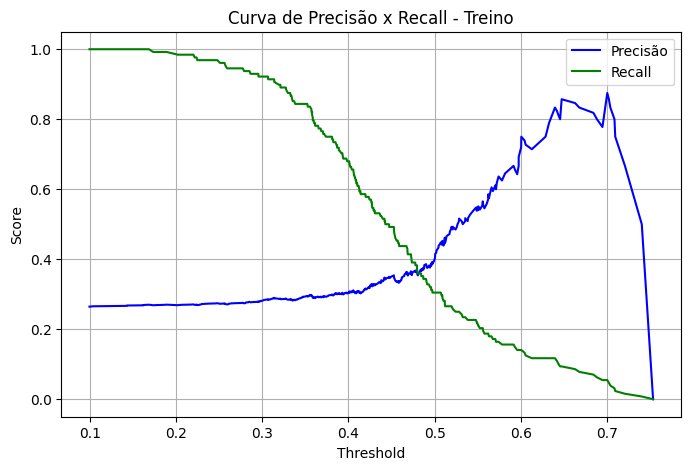

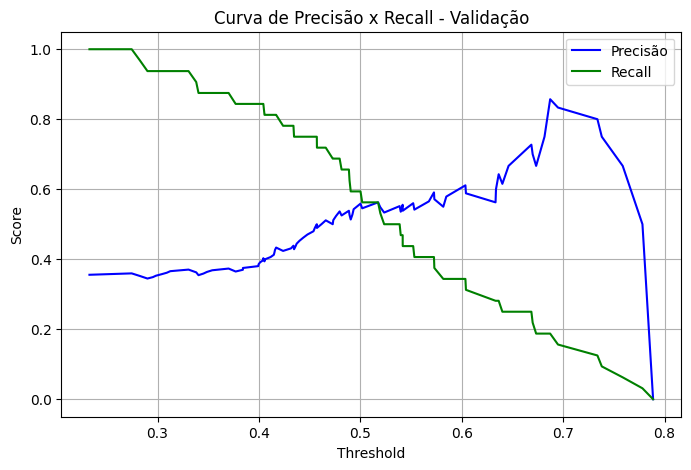

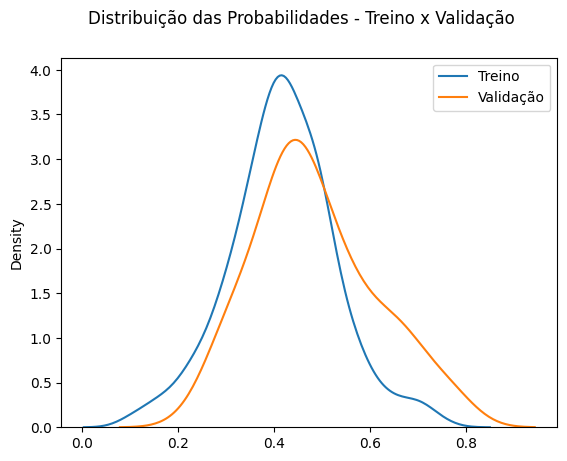

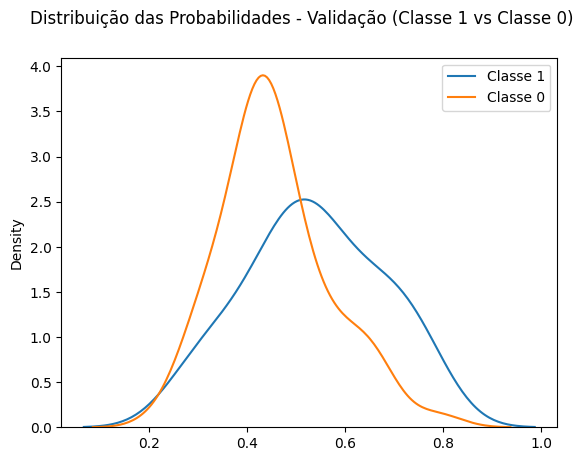

In [28]:
recall_minimo = None
precisao_minima = 0.7
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [ ]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [ ]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    #, class_weight={0:2.5, 1:1} # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[13]	valid_0's auc: 0.714286	valid_0's binary_logloss: 0.635803
Treinamento LGBM concluído. Melhor iteração: 13

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.786
AUC na validação: 0.527
Diferença AUC (Treino - Validação): 0.260
PROVÁVEL OVERFITTING
PR AUC no treino: 0.467
PR AUC na validação: 0.435
Diferença PR AUC (Treino - Validação): 0.032
F1 Score no treino: 0.475
F1 Score na validação: 0.215


(np.float64(0.7862949773380108),
 np.float64(0.526668508748471),
 np.float64(0.25962646858953975),
 np.float64(0.46680228409528235),
 np.float64(0.43495651913598127),
 np.float64(0.47525495314198424),
 np.float64(0.21450849721612944))

Avaliar e logar modelo
MLflow Run ID: a3aa057e85394ce7accf3a2f66f0459c para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.768
AUC na validação: 0.572

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.786
  Precisão média (em 453 janelas com previsão positiva): 0.369
  Recall médio: 0.853

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 28 janelas com previsão positiva): 0.858
Recall médio: 0.174
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 15
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run a3aa057e85394ce7accf3a2f66f0459c


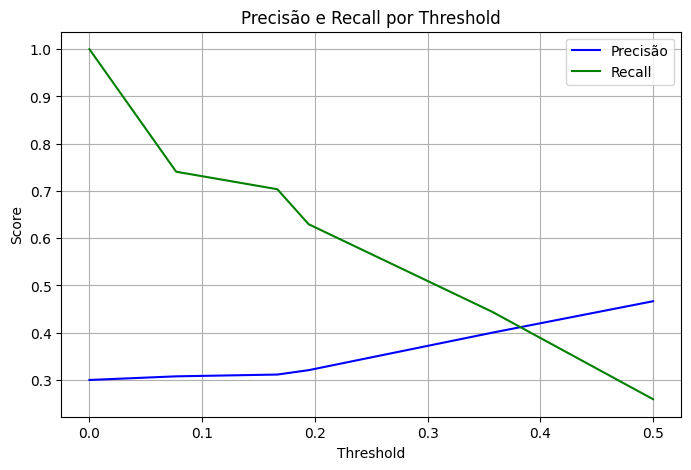

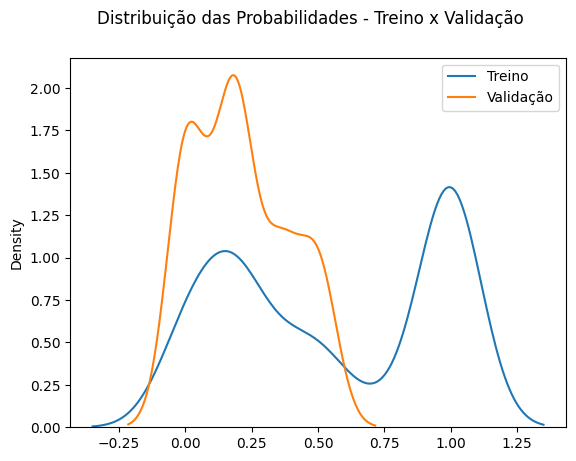

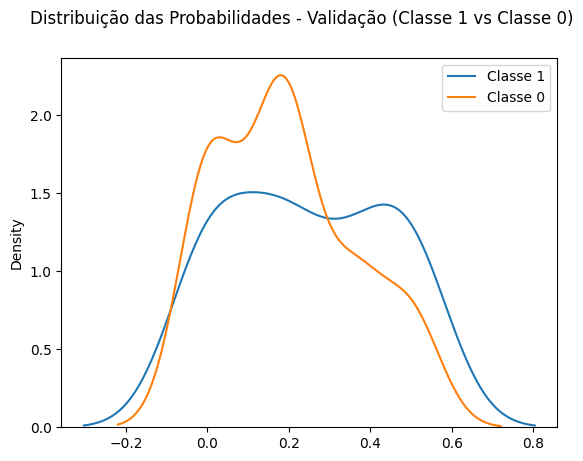

In [ ]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

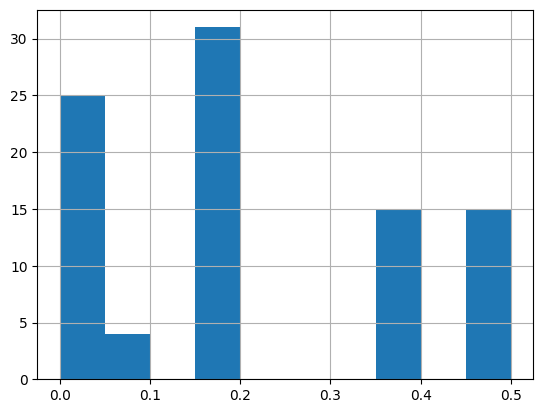

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [ ]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


close_vs_adc_close_mean_geral            593.602402
adc_correl_com_principal_BEEF3           301.161100
dolar_trend                              168.918600
close_amplitude_norm_atr_principal        90.541520
adc_correl_com_principal_BRFS3            84.953588
macd_signal_mean                          59.739935
macd_signal_ultimo_norm_atr_principal     52.640001
adc_atr_pct_ultimo_BEEF3                  48.530800
tr_std                                    32.812199
ibov_trend                                23.509001
macd_ultimo_norm_atr_principal            22.926100
adc_rsi_ultimo_JBSS3                      22.244801
close_trend                               17.977699
adc_correl_com_principal_JBSS3            16.024582
correl_papel_ibov                         11.575900
dtype: float64

In [ ]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

In [ ]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(0.0),
 30: np.float64(0.2811688311688311),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(0.5968266852195424),
 50: np.float64(nan)}

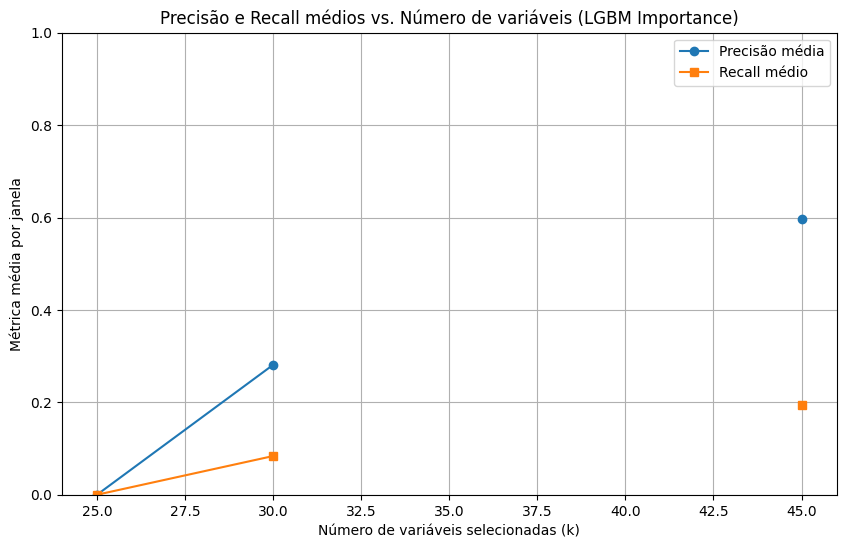

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


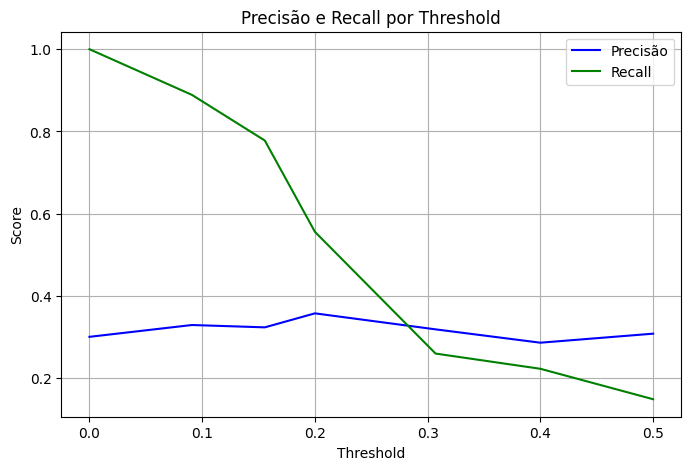

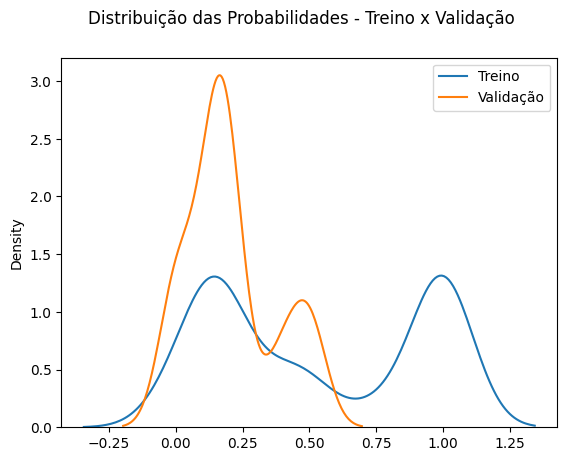

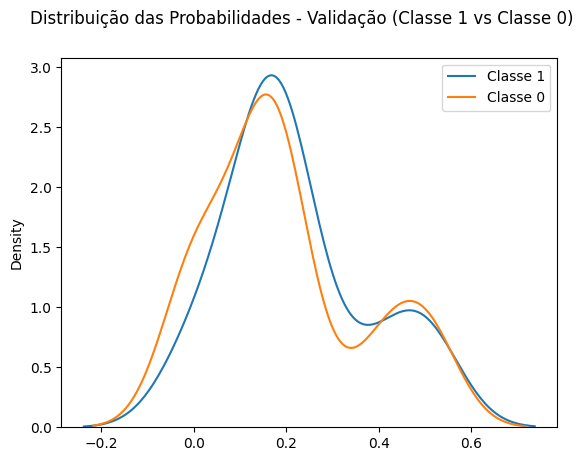

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

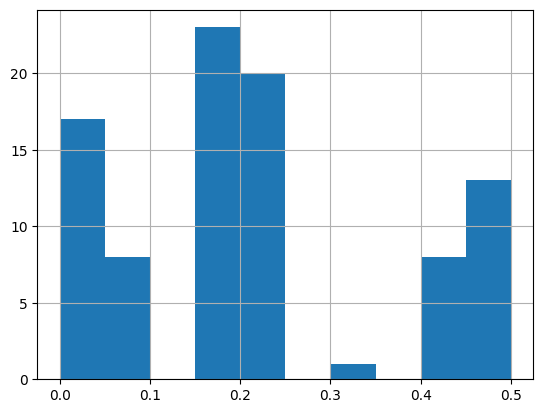

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64